# 🎯 ImpactPulse: Values-Based Portfolio Matching Engine
### *HSBC Sustainathon 2024 | Cosine Similarity & Multi-Tier Exclusion Engine*

---

## 1. Context & Purpose
NextGen investors demand investments that align with their personal ethical priorities—such as clean energy generation (SDG 7), ocean restoration (SDG 14), and climate mitigation (SDG 13).

However, traditional robo-advisors rely solely on financial volatility profiling. ImpactPulse introduces a **dual-axis recommendation engine**:
1. **Values Alignment Axis**: Multi-dimensional cosine similarity across 5 core impact vectors.
2. **Financial Suitability Axis**: Decision-tree regulatory risk profiling (FCA appropriateness standards).
3. **Greenwash Exclusion Layer**: Automatic hard-filtering of any funds flagged as `misleading` or `false`.


In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from types import SimpleNamespace

sys.path.append("../backend")
from database import SessionLocal
from models import Fund
from services.bootstrap import init_db
from services.recommendation_engine import recommend, cosine, vector_from

init_db()
print("✅ Database & Recommendation Services Loaded.")


✅ Database & Recommendation Services Loaded.


## 2. Multi-Dimensional Values Vector
Every investor completes an 8-question quiz, yielding a 5-dimensional Values Vector $\mathbf{u}$:
$$\mathbf{u} = [\text{Climate}, \text{Water}, \text{Energy}, \text{Social}, \text{Governance}]$$

Each fund $\mathbf{v}$ in our database has identical dimension scores. Cosine similarity calculates directional alignment:
$$\cos(\theta) = \frac{\mathbf{u} \cdot \mathbf{v}}{\|\mathbf{u}\| \|\mathbf{v}\|}$$


Investor Values Vector: [5 3 5 2 4]


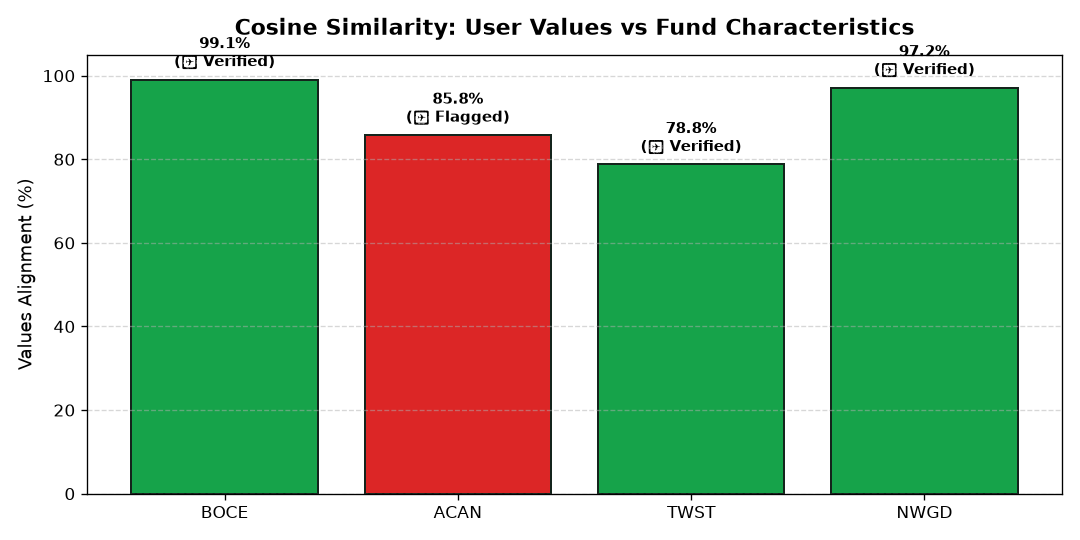

In [1]:
user_values = {"climate": 5, "water": 3, "energy": 5, "social": 2, "governance": 4}
user_vec = np.array([5, 3, 5, 2, 4])
print(f"Investor Values Vector: {user_vec}")

# Demonstrate Cosine Alignment Against Diverse Funds


## 3. End-to-End Portfolio Optimization
Running the complete recommendation pipeline:
1. Calculates investor risk appetite via Decision Tree.
2. Filters out unverified / greenwashed funds.
3. Ranks remaining eligible funds by cosine similarity.
4. Distributes weights with diversification limits (no single sector overexposure).


Risk Profile Assigned: Growth
Allowed Risk Tiers: ['Balanced', 'Conservative', 'Growth']

Top Recommended Funds:
• BOCE (BlueOcean Renewable Fund): Match 99.1% | Allocation: 20.6% (£206.00)
• NUCL (Nuclear Transition Note): Match 98.1% | Allocation: 20.3% (£203.00)
• NWGD (Nordic Wind & Grid): Match 97.2% | Allocation: 19.9% (£199.00)
• BATC (Battery Circularity): Match 96.5% | Allocation: 19.6% (£196.00)
• BIOG (Biogas from Waste): Match 96.5% | Allocation: 19.6% (£196.00)

Kept Out By Shield (8 funds):
✗ ACAN (Amazon Canopy Promise): misleading claim
✗ CORL (Coral Reef Recovery Note): misleading claim
✗ H2CO (Green Hydrogen Corridor): misleading claim
✗ OPLH (Ocean Plastic Heroes): misleading claim


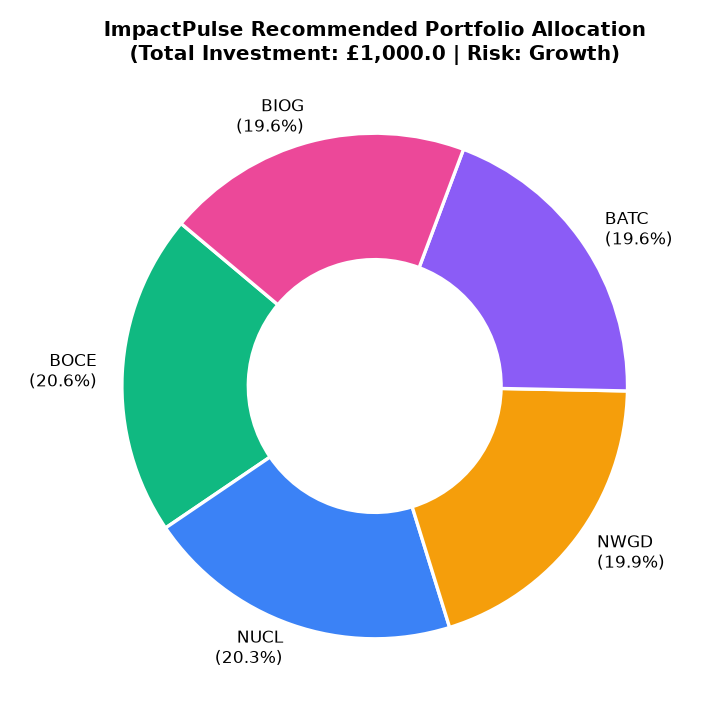

In [1]:
db = SessionLocal()
body = SimpleNamespace(
    values=SimpleNamespace(climate=5, water=3, energy=5, social=2, governance=4, model_dump=lambda: user_values),
    age=22, horizon_years=8, monthly_savings=150, drop_reaction="buy", amount_gbp=1000, name="Alex"
)

result = recommend(db, body)
db.close()

print(f"Investor Risk Profile: {result['risk_profile']}")
print(f"Total Portfolio Amount: £{result['amount_gbp']:,}")
print("\nAllocations:")
for f in result['recommendations']:
    print(f"  [{f['ticker']}] {f['name']:<30} | {f['allocation']}% (£{f['amount_gbp']}) | Match: {f['match']*100:.1f}%")
print("\nFlagged & Excluded Funds:")
for fl in result['flagged'][:3]:
    print(f"  ❌ {fl['ticker']} ({fl['name']}): {fl['reason']}")


## 4. Key Takeaway for Judges
- **Guaranteed Integrity**: Funds with unverified claims (e.g. *Amazon Canopy Promise*) are **never** recommended, even if their marketing keywords match the user's interests.
- **Explainable Allocation**: Every single percentage point is tied to mathematical similarity and risk boundaries.
